# Impulsive limit and rotating-wave approximation for the THz chain of Example 1

QuDPy-FDGF evaluates the response of **impulsive pulses in the rotating-wave approximation (RWA)**. This notebook measures how good that description is for the six-site XXZ chain at 4 K, by comparing the third-order rephasing map of the solver with a time-domain calculation, independent of resolvents and pathways, in which three Gaussian pulses of finite duration drive the system. In this notebook you will:

- check the time-domain engine (`validation/pulses.py`) against a non-perturbative propagation with phase cycling;
- read the maps computed by `analysis/example2_pulses.py` for ten pulse durations $\sigma$, with the RWA field and with the real field;
- measure three errors: the error of the impulsive limit (finite pulse, RWA, against QuDPy-FDGF), the error of the RWA (real field against RWA field at the same $\sigma$), and their sum (real field against QuDPy-FDGF);
- see that no duration brings the total error below about 3 % when the carrier sits on the magnon.

The method is written up in `notes/Moteur_impulsions_finies.pdf` of the article repository. Natural units: $\hbar=1$, energies in meV, times in meV$^{-1}$ (1 meV$^{-1}$ = 0.658 ps). The carrier is the bright magnon energy, 1.122 meV = 0.271 THz.

## 0. Imports and the maps

In [1]:
import os

for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")

import json
import sys

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np

import pulses
from models import ANALYSIS_FIGURES, DATA, results_dirs

results_dirs()
saved = np.load(DATA / "example2_pulses.npz")
sigmas, reference = saved["sigmas"], saved["fdgf"]
print("pulse durations (meV^-1):", sigmas)
print("map shape (omega_1q, omega_emit):", reference.shape, "  eta =", float(saved["eta"]), "meV")

pulse durations (meV^-1): [0.02 0.05 0.1  0.2  0.4  0.7  1.   1.5  2.   3.  ]
map shape (omega_1q, omega_emit): (60, 60)   eta = 0.03 meV


## 1. The engine against a non-perturbative propagation

`phase_cycled_polarization` propagates the density matrix under the full (or rotating-wave) field for 64 combinations of the phases of the three pulses and projects the component $e^{i(\varphi_1-\varphi_2-\varphi_3)}$; the orders five and higher are removed by Richardson extrapolation on the amplitude. The hierarchy of `Hierarchy.polarization` gets the same signal from the multilinear terms of the three pulses, exactly in the third order. Here the pulses have $\sigma=0.5$ meV$^{-1}$ and are 1.5 meV$^{-1}$ apart, so that they overlap.

In [2]:
energies, mu, mu_plus, rho0 = pulses.chain_system()
carrier = float(energies[energies > 0.5].min())          # lowest one-magnon level: the bright k = 0 magnon
print(f"carrier = {carrier:.4f} meV")
for rwa in (True, False):
    hierarchy = pulses.Hierarchy(energies, mu, mu_plus, rho0, sigma=0.5, carrier=carrier, rwa=rwa, dt=0.02)
    times_1, trajectory = hierarchy.first_order()
    times, values, _, _ = hierarchy.polarization(1.5, 0.0, times_1, trajectory)
    cycled_times, cycled = pulses.phase_cycled_polarization(energies, mu, mu_plus, rho0, 0.5, carrier, rwa, 1.5,
                                                            amplitude=0.01, dt=0.02)
    common = values[np.isin(np.round(times, 6), np.round(cycled_times, 6))]
    difference = np.max(np.abs(common - cycled)) / np.max(np.abs(common))
    print(f"{'rotating-wave field' if rwa else 'real field':<20} hierarchy against phase cycling: {difference:.1e}")
    assert difference < 1e-5

carrier = 1.1224 meV


rotating-wave field  hierarchy against phase cycling: 1.5e-07


real field           hierarchy against phase cycling: 4.4e-07


## 2. The three errors

For each $\sigma$ the complex $60\times60$ maps $S_{\rm RWA}$ and $S_{\rm real}$ are compared with the impulsive response $S_{\rm F}$ of QuDPy-FDGF, up to one complex scale $c$ (the area of the pulses cubed, with phases and the factor $a^3$ of the field) fitted by least squares:

$$
E_{\rm pulse}=\frac{\|S_{\rm RWA}-c\,S_{\rm F}\|}{\|S_{\rm RWA}\|},\qquad
E_{\rm RWA}=\frac{\|S_{\rm real}-S_{\rm RWA}\|}{\|S_{\rm RWA}\|},\qquad
E_{\rm total}=\frac{\|S_{\rm real}-c'\,S_{\rm F}\|}{\|S_{\rm real}\|}.
$$

In [3]:
rows = []
print(f"{'sigma':>6}{'FWHM (ps)':>11}{'|c|/area^3':>12}{'E_pulse':>10}{'E_RWA':>10}{'E_total':>10}")
for sigma in sigmas:
    rwa_map, real_map = saved[f"rwa_{sigma:g}"], saved[f"full_{sigma:g}"]
    scale, e_pulse = pulses.scale_and_error(rwa_map, reference)
    scale_real, e_total = pulses.scale_and_error(real_map, reference)
    e_rwa = np.linalg.norm(real_map - rwa_map) / np.linalg.norm(rwa_map)
    area = sigma * np.sqrt(2 * np.pi)
    fwhm_ps = 2.3548 * sigma * 0.6582
    rows.append((float(sigma), fwhm_ps, abs(scale) / area**3, e_pulse, e_rwa, e_total))
    print(f"{sigma:>6g}{fwhm_ps:>11.2f}{abs(scale) / area**3:>12.4f}{e_pulse:>10.1e}{e_rwa:>10.1e}{e_total:>10.1e}")
rows = np.array(rows)
best = int(np.argmin(rows[:, 5]))
print(f"smallest total error: {100 * rows[best, 5]:.1f} % at sigma = {rows[best, 0]:g} meV^-1 (pulse FWHM {rows[best, 1]:.2f} ps)")

 sigma  FWHM (ps)  |c|/area^3   E_pulse     E_RWA   E_total
  0.02       0.03      0.9995   1.0e-03   8.8e-02   8.5e-02
  0.05       0.08      0.9989   2.2e-03   8.7e-02   8.4e-02
   0.1       0.15      0.9979   4.2e-03   8.4e-02   8.1e-02
   0.2       0.31      0.9958   8.4e-03   7.2e-02   7.0e-02
   0.4       0.62      0.9914   1.7e-02   4.0e-02   4.2e-02
   0.7       1.08      0.9844   2.9e-02   8.3e-03   2.9e-02
     1       1.55      0.9768   4.1e-02   4.0e-03   4.0e-02
   1.5       2.32      0.9629   6.1e-02   3.8e-03   6.0e-02
     2       3.10      0.9477   8.1e-02   3.5e-03   8.0e-02
     3       4.65      0.9138   1.2e-01   3.1e-03   1.2e-01
smallest total error: 2.9 % at sigma = 0.7 meV^-1 (pulse FWHM 1.08 ps)


**Reading the table.**

- The impulsive limit alone is good for short pulses. $E_{\rm pulse}$ grows linearly with $\sigma$, about 4 % per meV$^{-1}$, from $10^{-3}$ at $\sigma=0.02$ meV$^{-1}$, where the time-domain engine and QuDPy-FDGF agree on the whole published map ($60\times60$ points, $\eta=0.03$ meV), and it passes 1 % near $\sigma=0.25$ meV$^{-1}$. It is the spectral filter of the pulse across the band of the map, which spans $\pm0.5$ meV around the carrier.
- The RWA error is a plateau of about 9 % for very short pulses and falls below 1 % for $\sigma\geq0.7$ meV$^{-1}$. It never exceeds 9 %: for a pulse centred on the magnon the counter-rotating terms of a real broadband field change the rephasing map by less than a tenth, even for the shortest pulses. Beyond $\sigma=1$ it settles near $3\times10^{-3}$ (probably integration error of the real-field run, not checked).
- The sum has a minimum of about 3 % near $\sigma=0.7$ meV$^{-1}$ (pulse FWHM 1.1 ps, spectral FWHM 3.4 meV = 0.8 THz): **with the carrier on the magnon there is no duration for which both approximations hold to better than a few per cent.**
- The scale $|c|/{\rm area}^3$ falls from 1 to 0.91 as the pulse lengthens, which is the same spectral filter seen in amplitude.

## 3. Figure

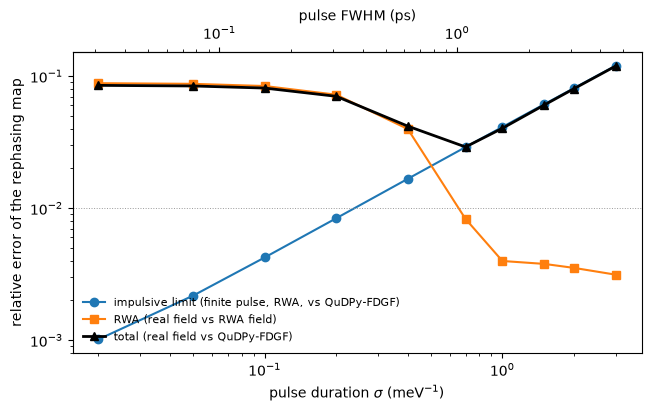

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 4.0), constrained_layout=True)
ax.loglog(rows[:, 0], rows[:, 3], "o-", label=r"impulsive limit (finite pulse, RWA, vs QuDPy-FDGF)")
ax.loglog(rows[:, 0], rows[:, 4], "s-", label=r"RWA (real field vs RWA field)")
ax.loglog(rows[:, 0], rows[:, 5], "k^-", lw=2, label=r"total (real field vs QuDPy-FDGF)")
ax.axhline(0.01, color="0.6", lw=0.7, ls=":")
ax.set_xlabel(r"pulse duration $\sigma$ (meV$^{-1}$)")
ax.set_ylabel("relative error of the rephasing map")
top = ax.secondary_xaxis("top", functions=(lambda s: 2.3548 * 0.6582 * s, lambda p: p / (2.3548 * 0.6582)))
top.set_xlabel("pulse FWHM (ps)")
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.savefig(ANALYSIS_FIGURES / "example2_pulses.pdf", bbox_inches="tight")
plt.show()

with open(DATA / "example2_pulses.json", "w") as handle:
    json.dump({"columns": ["sigma_meV-1", "fwhm_ps", "scale_over_area3", "E_pulse", "E_RWA", "E_total"], "rows": rows.tolist(),
               "smallest_total_error": float(rows[best, 5]), "sigma_of_smallest_total_error": float(rows[best, 0])}, handle, indent=1)

## Summary

- The time-domain engine reproduces a non-perturbative, phase-cycled propagation to $10^{-7}$, and QuDPy-FDGF to $10^{-3}$ on the published map in the impulsive limit: an independent check of the third-order response of the chain, with its eight sequences, signs and kernel.
- With the carrier on the bright magnon, the impulsive limit costs about 4 % per meV$^{-1}$ of pulse duration, the RWA costs up to 9 % for very short pulses and under 1 % beyond 0.7 meV$^{-1}$, and the sum cannot be brought below about 3 %.
- Pulses of real THz sources are broader than this and centred higher (see `notes/Moteur_impulsions_finies.pdf`): the carrier should then be varied as well. The maps for this study were not computed.